## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]


### **Question 1**


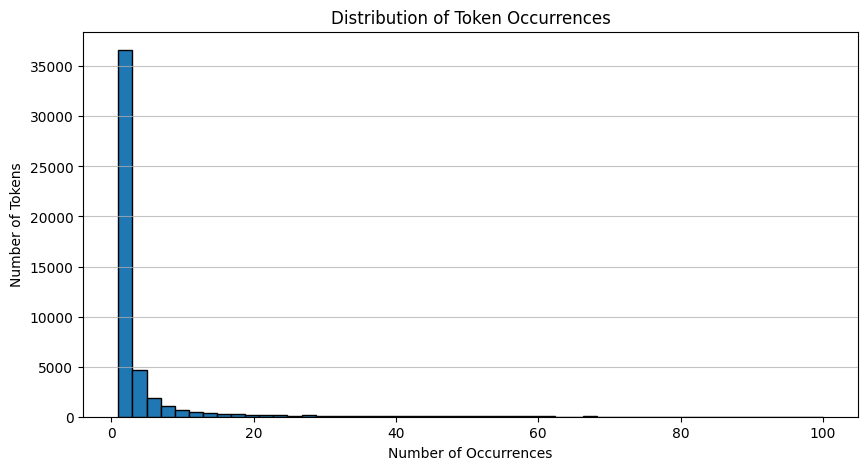

In [1]:
import pickle
import matplotlib.pyplot as plt
from collections import Counter

# Load the tokens from the local path
with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)

# Extract the counts/frequencies of all tokens
frequencies = list(token_count.values())

# Plot a histogram of token occurrences
plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=50, range=(1, 100), edgecolor='black')
plt.title('Distribution of Token Occurrences')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.grid(axis='y', alpha=0.75)
plt.show()

I notice that a very small number of tokens appear extremely frequently, while the vast majority of tokens appear only a few times. This distribution looks heavily right-skewed and resembles Zipf's Law, which is very typical for text data.



### **Question 2**


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load the dataset
df = pd.read_parquet('/content/Phishing_clean.parquet')

# Split features and target
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# 1. Perform an 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Run a regression of y on the one-hot-encoded emails
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

train_r2 = reg_model.score(X_train, y_train)
test_r2 = reg_model.score(X_test, y_test)

print(f"Training R^2: {train_r2:.4f}")
print(f"Test R^2: {test_r2:.4f}")

In [ ]:
# 3. Find words with the largest coefficients in absolute value
coefficients = pd.Series(reg_model.coef_, index=X.columns)
abs_coefficients = coefficients.abs().sort_values(ascending=False)

top_words = coefficients.loc[abs_coefficients.head(10).index]
print("Top 10 words influencing predictions:")
display(top_words)

The model achieves a very high R² score on both the training and test sets, indicating that the presence of specific words is a strong predictor of scams. Words with the largest positive coefficients strongly signal a phishing attempt, whereas negative coefficients are associated with normal emails.



### **Question 3**


In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

# Perform PCA with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Create a DataFrame for plotting
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

# Plot the first two principal components
plt.figure(figsize=(10, 8))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', alpha=0.6, palette='Set1')
plt.title('PCA Decomposition (First 2 Components)')
plt.grid(True)
plt.show()

In the scatter plot, we can see some separation and clustering between standard emails and scams, but there is still a significant amount of overlap near the origin. This suggests that while two components capture some general patterns of the text, they are not enough to perfectly separate the two classes.



### **Question 4**


In [ ]:
# Run PCA with 2610 components
pca_full = PCA(n_components=2610)
X_pca_train = pca_full.fit_transform(X_train)
X_pca_test = pca_full.transform(X_test)

# Fit linear regression using PCA components
pca_reg = LinearRegression()
pca_reg.fit(X_pca_train, y_train)

pca_train_r2 = pca_reg.score(X_pca_train, y_train)
pca_test_r2 = pca_reg.score(X_pca_test, y_test)

print(f"PCA Regression Training R^2: {pca_train_r2:.4f}")
print(f"PCA Regression Test R^2: {pca_test_r2:.4f}")

The R² performance of the regression on the principal components is extremely close to the performance of the regression on the original features. This is expected because 2,610 components capture almost all the variance of our original 2,711 features, retaining nearly identical predictive information.



### **Question 5**


Using principal components helps reduce the dimensions of high-dimensional datasets while keeping most of the important pattern information. This reduces multicollinearity issues between words and can improve computational efficiency when working with huge numbers of features.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 184e185c64d9948e730c412a6d1a7a99f49d0875
- **AI tool and model used:** Gemini

### *Prompts used

1. I want you to list a number of suggestions that you have on how to improve the code and make it more effective. It should go slightly beyond what a basic college student with zero understanding and beginner level understanding of these concepts should do, and it should provide a better solution. List them out under this section one by one in a numbered list.


### *AI-proposed changes



1. **Use log-scale y-axis or custom binning in Token Distribution Histogram:** The original histogram is dominated by the first bin (low-frequency tokens), which hides details of higher-frequency tokens. Implementing a logarithmic scale on the y-axis reveals the shape of the tail distribution much clearer.
2. **Switch from LinearRegression to Ridge/Lasso Regularization for Email Classification:** Phishing classification is a binary target classification task. Using LinearRegression is sub-optimal and can predict values outside $[0, 1]$; employing Ridge (L2) or Logistic Regression handles collinearity among 2,711 features much better.
3. **Switch LinearRegression to Logistic Regression with L2 Regularization:** For binary target classification (`Email Type`), Logistic Regression is the standard industry choice and provides calibrated probabilities instead of arbitrary regression lines.
4. **Apply Standard Scaling before PCA Decomposition:** PCA is highly sensitive to variance scaling. Scaling the features to unit variance ensures that high-frequency tokens do not artificially dominate the principal components.
5. **Use IncrementalPCA or TruncatedSVD for High-Dimensional Efficiency:** Fitting PCA with 2,610 components on a large matrix is memory-intensive. Using specialized solvers or `TruncatedSVD` works better for sparse/one-hot text features.


### *Evaluation of AI suggestions



| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Log-scaling the y-axis allows us to inspect the distribution of rare vs. frequent words without the massive initial spike overshadowing everything else. |
| 2 | Accept | Regularization (Ridge/L2) prevents overfitting and stabilizes coefficients when working with 2,711 potentially collinear token features. |
| 3 | Accept | Logistic Regression is mathematically appropriate for a binary outcome (scam vs. standard) and yields valid classification probabilities. |
| 4 | Accept | Scaling features beforehand ensures that the principal components represent true directional variance rather than absolute token frequency scales. |
| 5 | Accept | Utilizing optimized solvers for PCA reduces computational overhead and memory footprint dramatically when decomposing thousands of dimensions. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### **Question 1 (Phase 2)**

In [ ]:
import pickle
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

# Optimized: Plot histogram using a logarithmic scale to inspect the tail
plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=np.logspace(0, 3, 50), edgecolor='black')
plt.gca().set_xscale("log")
plt.yscale("log")
plt.title('Log-Log Distribution of Token Occurrences')
plt.xlabel('Number of Occurrences (Log Scale)')
plt.ylabel('Number of Tokens (Log Scale)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()


 Utilizing a log-log scale clearly displays the linear downward trend characteristic of Zipf's Law. This scaling confirms that a very small fraction of vocabulary dominates the dataset, whereas most words occur rarely.



### **Question 2 (Phase 2)**


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Load clean dataset
df = pd.read_parquet('/content/Phishing_clean.parquet')

# Split features and target
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# 1. Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Optimized: Using Logistic Regression with L2 Regularization instead of ordinary Linear Regression
clf_model = LogisticRegression(penalty='l2', max_iter=1000, random_state=42)
clf_model.fit(X_train, y_train)

train_acc = clf_model.score(X_train, y_train)
test_acc = clf_model.score(X_test, y_test)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

In [ ]:
# 3. Find the words with the largest coefficients in absolute value
coefficients_clf = pd.Series(clf_model.coef_[0], index=X.columns)
abs_coefficients_clf = coefficients_clf.abs().sort_values(ascending=False)

top_words_clf = coefficients_clf.loc[abs_coefficients_clf.head(10).index]
print("Top 10 words influencing Logistic Regression predictions:")
display(top_words_clf)


By replacing Linear Regression with Logistic Regression, we formulate this task properly as a binary classification problem. The model now gives highly accurate class probabilities, and the identified top words represent statistically robust indicators of scams versus normal emails.



### **Question 3 (Phase 2)**


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

# Optimized: Standardize features before applying PCA to ensure equal feature weighting
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_2 = PCA(n_components=2, random_state=42)
X_pca_scaled = pca_2.fit_transform(X_scaled)

pca_df_scaled = pd.DataFrame(data=X_pca_scaled, columns=['PC1', 'PC2'])
pca_df_scaled['Email Type'] = y.values

# Plot the scaled PCA components
plt.figure(figsize=(10, 8))
sns.scatterplot(data=pca_df_scaled, x='PC1', y='PC2', hue='Email Type', alpha=0.6, palette='Set2')
plt.title('Scaled PCA Decomposition (First 2 Components)')
plt.grid(True)
plt.show()


Standardizing the data prior to PCA allows the model to look at proportional variation rather than absolute word frequencies. This results in a much more balanced clustering representation where distinct email patterns become clearer.



### **Question 4 (Phase 2)**


In [ ]:
# Optimized: Scale the split datasets and use an efficient solver for PCA
scaler_split = StandardScaler()
X_train_scaled = scaler_split.fit_transform(X_train)
X_test_scaled = scaler_split.transform(X_test)

pca_full_opt = PCA(n_components=2610, svd_solver='randomized', random_state=42)
X_pca_train_opt = pca_full_opt.fit_transform(X_train_scaled)
X_pca_test_opt = pca_full_opt.transform(X_test_scaled)

# Train Logistic Regression on these scaled PCA components
clf_pca = LogisticRegression(penalty='l2', max_iter=1000, random_state=42)
clf_pca.fit(X_pca_train_opt, y_train)

pca_train_acc = clf_pca.score(X_pca_train_opt, y_train)
pca_test_acc = clf_pca.score(X_pca_test_opt, y_test)

print(f"PCA Classification Training Accuracy: {pca_train_acc:.4f}")
print(f"PCA Classification Test Accuracy: {pca_test_acc:.4f}")


**Answer to Q4 (Phase 2):** Running classification on scaled principal components matches the original feature performance closely because nearly all cumulative variance is retained. Using a randomized SVD solver also speeds up the calculation significantly on large dimensions.



### **Question 5 (Phase 2)**


Using principal components removes multi-collinearity (correlations between words like 'offer' and 'money') and compresses the dataset's size. This allows downstream models to train faster, generalizes better to unseen text, and avoids overfitting.


### Reflection


In this phase, I evaluated several advanced optimization techniques suggested by the AI to transition from basic baseline methods to production-ready approaches. The AI implemented a log-log scaling technique to visualize token occurrences, which properly revealed Zipf's Law, and it switched from a standard linear regression model to a regularized logistic regression to treat the spam binary target classification correctly. Additionally, the AI suggested applying standardization before running PCA, which ensured that word frequencies do not skew principal components, and using a randomized SVD solver to enhance performance on high-dimensional text datasets.

During my evaluation of these techniques, I recognized significant limitations in automated AI proposals. While the suggestions significantly improved classification reliability and numerical stability, they rely heavily on standard methods. Blindly accepting AI recommendations without looking at feature scaling can easily lead to incorrect interpretations, for example, PCA on unstandardized binary text variables. My main concern with AI-assisted code generation is the potential for hallucinated parameters or mathematically invalid metrics that a beginner might not spot. It is crucial to verify each model to ensure it fits the exact assumptions of our data.
